In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib_map_utils.core.scale_bar import scale_bar

In [2]:
gdf = gpd.read_file("Alqueva_Reservoir.geojson")
# Keep only relation
reservoir = gdf[gdf["@id"] == "relation/8988700"].copy()
# Reproject 
reservoir = reservoir.to_crs("EPSG:3763")

In [3]:
# Km² area
area_km2 = reservoir.geometry.area.sum() / 1_000_000
# Attributes
capacity = float(reservoir["reservoir:capacity"].iloc[0])
useful_capacity = float(reservoir["reservoir:useful_capacity"].iloc[0])

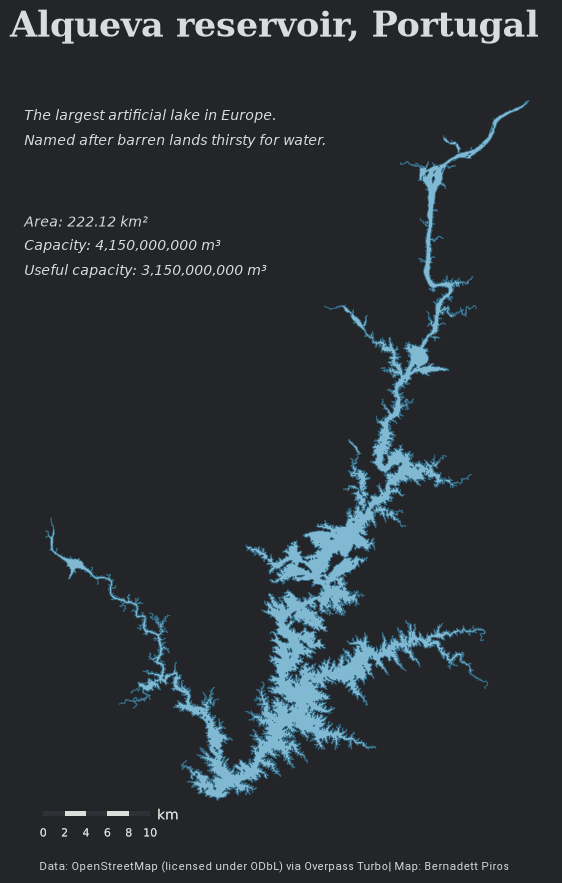

In [4]:
fig, ax = plt.subplots(figsize=(10, 10), facecolor="#232529")

reservoir.plot(ax=ax, color="#80B9D1", ec="#326782", lw=0.5)

# Scale bar
scale_bar(ax=ax, location="lower left", style="boxes",
    bar={
        "projection": 3763,
        "unit": "km",
        "max": 10,
        "major_div": 5,
        "minor_type": "none",
        "height":0.05,
        "facecolors": ["#2f3137", "#dde0da"],
        "edgecolor": "none",        
        "edgewidth": 0
    },
    aob={
        "bbox_to_anchor": (0.01, -0.02),
        "bbox_transform": ax.transAxes
    },
    labels={
        "style": "major",
        "loc": "below",
        "fontsize": 8,
        "pad": 0
    },
    units={
        "loc": "bar"
    },
    text={
        "textcolor": "#dde0da",
        "stroke_color": "#2f3137",
        "stroke_width": 0.1,
        "fontsize": 10
    }
)

# Title
fig.text(0.5, 0.9,
         "Alqueva reservoir, Portugal", 
         size=25, weight="bold", color="#d9dbdf", fontfamily="serif", ha="center", va="bottom")

# Subtitle
fig.text(0.25, 0.8, 
         f"The largest artificial lake in Europe.\n"
         f"Named after barren lands thirsty for water.", 
         size=10, color="#d9dbdf", fontstyle="italic", linespacing=1.8)

# Capacity subtitle
fig.text(0.25, 0.67,
         f"Area: {area_km2:,.2f} km²\n"
         f"Capacity: {capacity:,.0f} m³\n"
         f"Useful capacity: {useful_capacity:,.0f} m³",
         size=10, color="#d9dbdf", fontstyle="italic", linespacing=1.8)

# Caption
fig.text(0.5, 0.075,
         "Data: OpenStreetMap (licensed under ODbL) via Overpass Turbo| Map: Bernadett Piros",
         size=8, color="#d9dbdf", fontfamily="Roboto", ha="center")    

ax.set_aspect("equal")
ax.axis("off")

#plt.show()

# Save 
fig.savefig("Alqueva_Reservoir.png", bbox_inches="tight", pad_inches=0.2) 